In [1]:
import os

In [2]:
!unzip "/content/drive/MyDrive/Colab Notebooks/food-101.zip" -d "/content/food_data"

Streaming output truncated to the last 5000 lines.
 extracting: /content/food_data/tacos/1023154.jpg  
 extracting: /content/food_data/tacos/1023947.jpg  
 extracting: /content/food_data/tacos/1026681.jpg  
 extracting: /content/food_data/tacos/1030289.jpg  
 extracting: /content/food_data/tacos/1033196.jpg  
 extracting: /content/food_data/tacos/1036030.jpg  
 extracting: /content/food_data/tacos/1042175.jpg  
 extracting: /content/food_data/tacos/1044043.jpg  
 extracting: /content/food_data/tacos/1058697.jpg  
 extracting: /content/food_data/tacos/1059239.jpg  
 extracting: /content/food_data/tacos/1059326.jpg  
 extracting: /content/food_data/tacos/1066762.jpg  
 extracting: /content/food_data/tacos/1070967.jpg  
 extracting: /content/food_data/tacos/1073468.jpg  
 extracting: /content/food_data/tacos/1075296.jpg  
 extracting: /content/food_data/tacos/1085243.jpg  
 extracting: /content/food_data/tacos/108529.jpg  
 extracting: /content/food_data/tacos/1086014.jpg  
 extracting: /

**Observation:** The Food-101 dataset was a zip file on Google Drive.

**Decision:** Unzip it so each food has its own folder.

**Result:** Images are ready in /content/food_data.

In [3]:
import numpy as np
import matplotlib.pyplot as plt


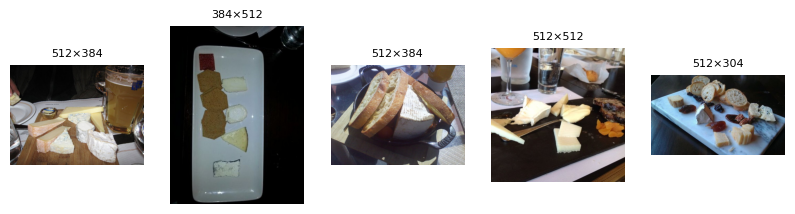

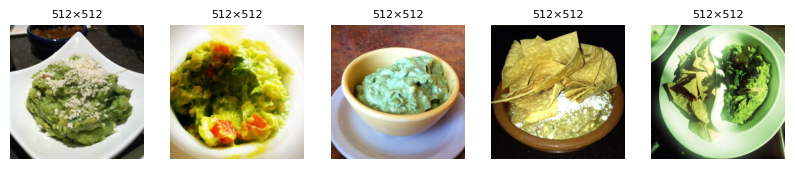

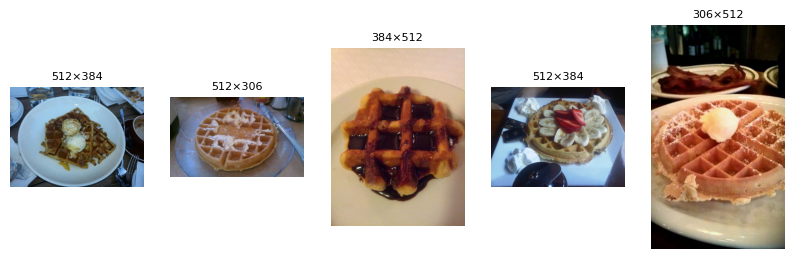

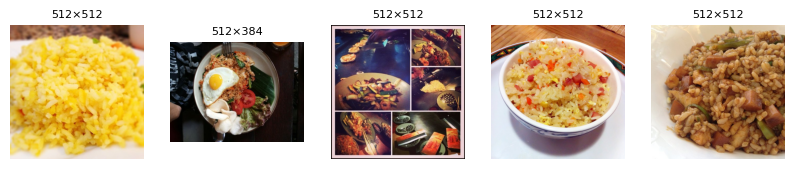

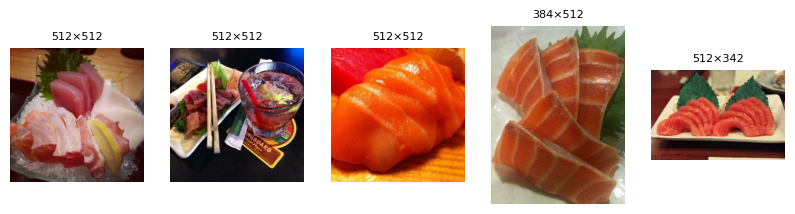

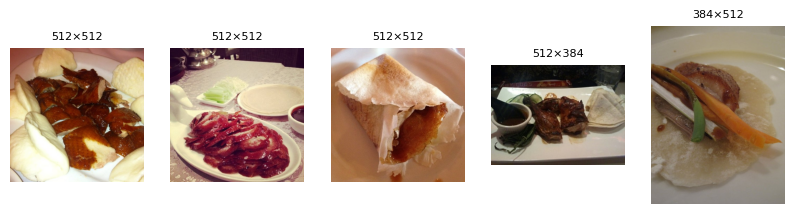

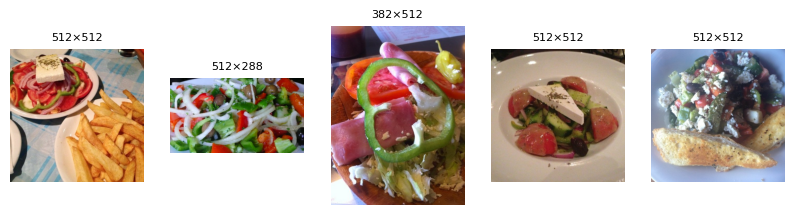

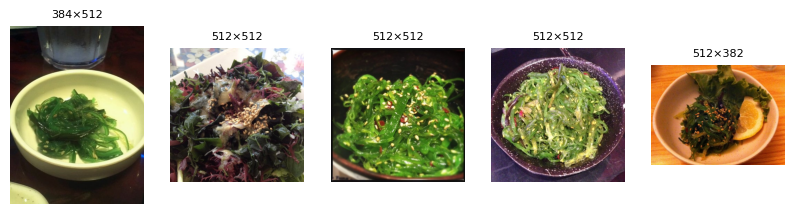

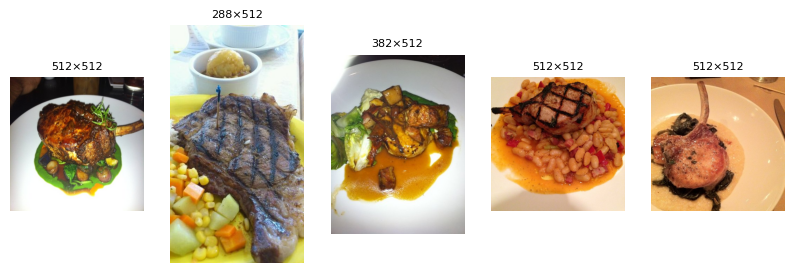

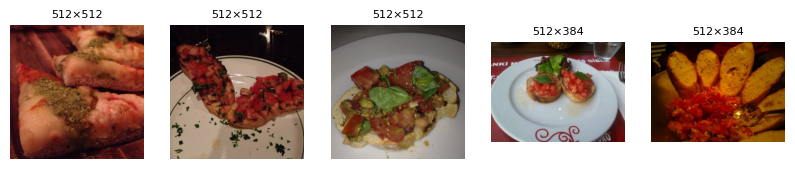

In [4]:
from PIL import Image

images = os.listdir("/content/food_data")

for image in images[:10]:
  path = os.path.join("/content/food_data",image)
  plt.figure(figsize=(10,10))
  i = 0

  for img in os.listdir(path)[:5]:
        img_path = os.path.join(path, img)

        with Image.open(img_path) as im:
            width, height = im.size

        plt.subplot(1, 5, i + 1)
        plt.axis("off")
        plt.title(f"{width}×{height}", fontsize=8)
        plt.imshow(plt.imread(img_path))
        i += 1
  plt.show()


**Observation:** Images come in different sizes (like 512×384, 512×512).

**Decision:** Resize every image to 224×224 later.

**Result:** Data looks correct, and we know resizing is needed.

In [5]:
import tensorflow as tf


In [6]:
train_data = tf.keras.utils.image_dataset_from_directory("/content/food_data",
                                                         subset = "training",
                                                         validation_split = 0.2,
                                                         seed = 42,
                                                         batch_size = 32,
                                                         image_size = (224, 224)
                                                      )
val_data = tf.keras.utils.image_dataset_from_directory("/content/food_data",
                                                       subset = "validation",
                                                       validation_split = 0.2,
                                                       seed = 42,
                                                       image_size = (224,224),
                                                       batch_size = 32)

Found 101000 files belonging to 101 classes.
Using 80800 files for training.
Found 101000 files belonging to 101 classes.
Using 20200 files for validation.


**Observation:** Found 101,000 images in 101 classes: 80,800 for training and 20,200 for validation.

**Decision:** 80/20 split, batch size 32, image size 224×224, seed 42.

**Result:** Train and validation datasets are ready.

32
32


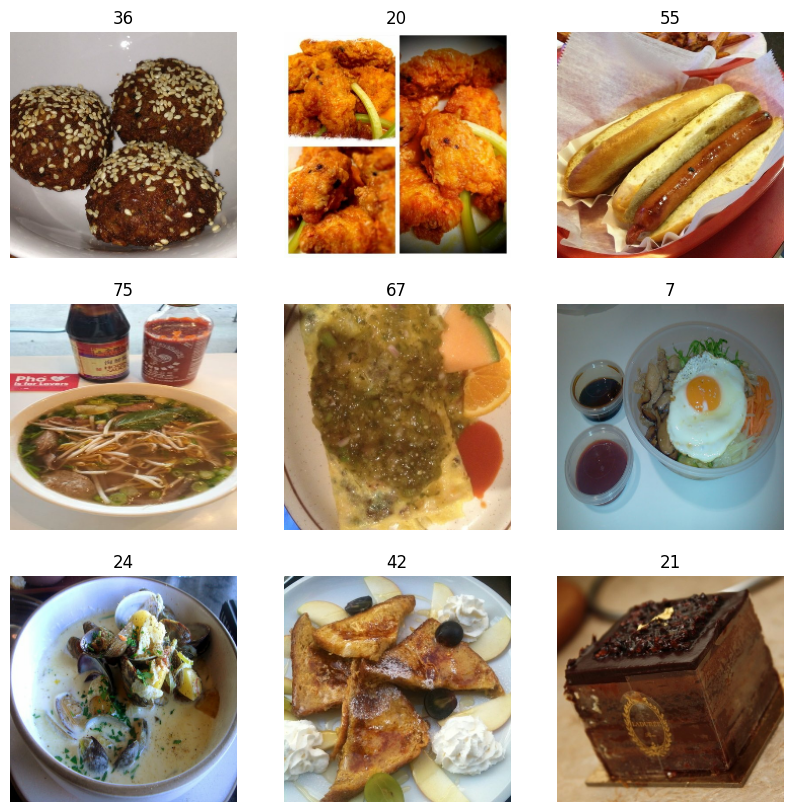

In [7]:
for images, labels in train_data.take(1):
    plt.figure(figsize=(10, 10))
    print(len(images))
    print(len(labels))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(int(labels[i]))
        plt.axis("off")

    plt.show()

**Observation:** Each batch has 32 images and 32 labels (numbers 0 to 100).

**Decision:** Check the data visually before training.

**Result:** Images and labels match, so the data is good.

In [8]:
class_names = train_data.class_names

In [9]:
print(len(train_data))
print(len(val_data))

2525
632


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Rescaling, Dropout, GlobalAveragePooling2D, BatchNormalization

In [11]:
normalization_layer = Rescaling(1.0/255)

train_data = train_data.map(lambda x,y : (normalization_layer(x), y))
val_data = val_data.map(lambda x,y : (normalization_layer(x), y))

**Observation:** Pixel values are between 0 and 255.

**Decision:** Divide by 255 so values are between 0 and 1.

**Result:** Data is normalized, so the model trains better.

In [12]:
model = Sequential()

model.add(Conv2D(32, (3,3), padding="same", activation="relu", input_shape=(224,224,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))


model.add(Conv2D(64, (3,3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))


model.add(Conv2D(128, (3,3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))


model.add(Conv2D(256, (3,3), padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPooling2D((2,2)))


model.add(GlobalAveragePooling2D())

model.add(Dense(512, activation="relu"))
model.add(Dropout(0.5))


model.add(Dense(101, activation="softmax"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Observation:** The CNN has 4 blocks of Conv + BatchNorm + MaxPool (32, 64, 128, 256 filters), then GlobalAveragePooling, Dense 512, Dropout 0.5, and a 101-class softmax output.

**Decision:** BatchNorm for stable training, Dropout to reduce overfitting, 101 outputs for 101 foods.

**Result:** A small model with about 573K parameters (2.19 MB).

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 101)            │        51,813 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 573,733 (2.19 MB)

 Trainable params: 572,773 (2.18 MB)

 Non-trainable params: 960 (3.75 KB)

In [14]:
model.compile(
    optimizer ="adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [19]:
history = model.fit(train_data, validation_data = val_data, epochs = 25, verbose = 1)

Epoch 1/25
 323/2525 ━━━━━━━━━━━━━━━━━━━━ 3:12 88ms/step - accuracy: 0.7341 - loss: 0.8814

KeyboardInterrupt: 

**Observation:** Trained for 25 epochs. Training accuracy kept going up, but validation accuracy stopped improving after about epoch 8.

**Decision:** Train for 25 epochs and watch both training and validation accuracy.

**Result:** Training finished successfully.
Got 73% in training it was quite good due to internet issue it is not saved properly.

In [18]:
model.save("food_classifier.keras")

In [17]:
from google.colab import files

files.download("food_classifier.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

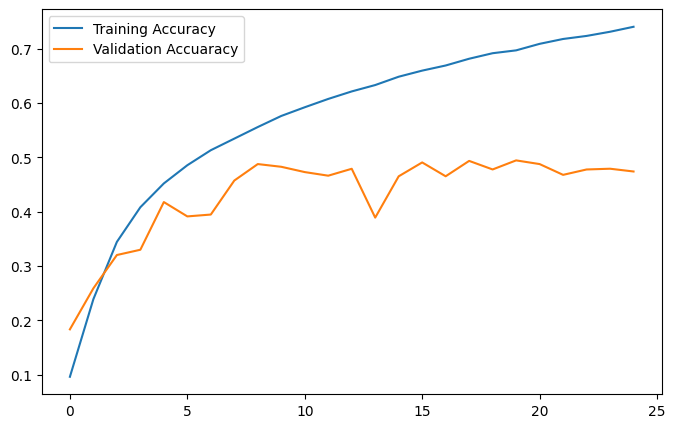

In [24]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuaracy")

plt.legend()
plt.show()

### Conclusion
Overall, 73% accuracy in training, we can imporove it by using below techniques.
It was very quite good model.

### How to improve it

- Transfer learning (MobileNetV2, EfficientNet, or ResNet) is the biggest win.

- Data augmentation (flip, rotate, zoom).

- Early stopping at about epoch 8–10.

- L2 regularization and a learning rate scheduler.